In [1]:
import pandas as pd

# Load datasets
raw = pd.read_excel("Mental_Health_Dataset_Version_2 (1).xlsx")
cleaned = pd.read_csv("cleaned_file.csv.xls")

def completeness_report(df):
    report = pd.DataFrame({ "Missing": df.isna().sum(), "Present": df.notna().sum() })

    report["Completeness (%)"] = ( report["Present"] / len(df) * 100 ).round(2)

    return report

print("RAW DATA COMPLETENESS")
print(completeness_report(raw))

print("\nCLEANED DATA COMPLETENESS")
print(completeness_report(cleaned))


RAW DATA COMPLETENESS
                                                    Missing  Present  \
Timestamp                                                 0      100   
Consent Agreement: I confirm that I am at least...        0      100   
Gender                                                    0      100   
Current Academic Year                                     0      100   
Current Living Arrangement                                0      100   
Average Daily Academic Screen Time (Hours)                0      100   
Average Daily Entertainment / Social Screen Tim...        0      100   
Over the past 2 weeks, how often have you felt ...        0      100   
How frequently do racing thoughts or repetitive...        0      100   
How often do you experience difficulty concentr...        0      100   
How often over the past month have you felt a l...        0      100   
How frequently do you experience sudden irritab...        0      100   
On average, how many hours of uninterrupte

In [2]:

rating_cols = [
    "stress_anxious",
    "racing_thoughts",
    "concentration",
    "low_motivation",
    "irritability",
    "evening_energy",
    "digestive_discomfort"
]

for col in rating_cols:
    values = pd.to_numeric(cleaned[col], errors="coerce")

    invalid = (
        values.isna()
        | ~values.between(1, 5)
        | (values % 1 != 0)
    )

    print(
        f"{col}: "
        f"{invalid.sum()} invalid values "
        f"out of {len(cleaned)}"
    )


stress_anxious: 0 invalid values out of 100
racing_thoughts: 0 invalid values out of 100
concentration: 0 invalid values out of 100
low_motivation: 0 invalid values out of 100
irritability: 0 invalid values out of 100
evening_energy: 0 invalid values out of 100
digestive_discomfort: 0 invalid values out of 100


In [3]:

import numpy as np

numeric_cols = [
    "sleep_hours",
    "screen_hours",
    "water_litres"
]

for col in numeric_cols:
    values = pd.to_numeric(cleaned[col], errors="coerce")

    invalid = (
        values.isna()
        | ~np.isfinite(values)
        | (values < 0)
    )

    print(f"\n{col}")
    print("Invalid values:", invalid.sum())
    print("Minimum:", values.min())
    print("Maximum:", values.max())



sleep_hours
Invalid values: 0
Minimum: 2.0
Maximum: 9.5

screen_hours
Invalid values: 0
Minimum: 0.5
Maximum: 8.5

water_litres
Invalid values: 0
Minimum: 0.5
Maximum: 5.5


In [4]:

categorical_cols = [
    "gender",
    "academic_year",
    "living_arrangement",
    "exercise_freq",
    "meal_regularity"
]

for col in categorical_cols:
    print(f"\n{col}")
    print(cleaned[col].value_counts(dropna=False))



gender
gender
Male      57
Female    43
Name: count, dtype: int64

academic_year
academic_year
2nd year    53
1st year    24
3rd year    18
4th year     5
Name: count, dtype: int64

living_arrangement
living_arrangement
Hostel                48
Living with Family    38
Flat/PG               14
Name: count, dtype: int64

exercise_freq
exercise_freq
1-2 days    32
3-4 days    26
5+ days     24
0 days      18
Name: count, dtype: int64

meal_regularity
meal_regularity
3 regular meals                  39
Skip 1 meal daily                31
Irregular/Random eating times    30
Name: count, dtype: int64


In [5]:

categorical_cols = [
    "gender",
    "academic_year",
    "living_arrangement",
    "exercise_freq",
    "meal_regularity"
]

for col in categorical_cols:
    original = cleaned[col].astype(str)

    standardized = original.str.strip().str.lower()

    print(f"{col}:")
    print("Original unique categories:", original.nunique())
    print("Standardized unique categories:", standardized.nunique())
    print()


gender:
Original unique categories: 2
Standardized unique categories: 2

academic_year:
Original unique categories: 4
Standardized unique categories: 4

living_arrangement:
Original unique categories: 3
Standardized unique categories: 3

exercise_freq:
Original unique categories: 4
Standardized unique categories: 4

meal_regularity:
Original unique categories: 3
Standardized unique categories: 3



In [6]:

columns = [
    "sleep_raw", "sleep_hours",
    "entertainment_screen_raw", "screen_hours",
    "water_raw", "water_litres"
]

print(cleaned[columns].head(15).to_string(index=False))



       sleep_raw  sleep_hours entertainment_screen_raw  screen_hours  water_raw  water_litres
               5          5.0               1-2 hours            1.5 2-3 litres           2.5
            7 hr          7.0                     3 hr           3.0    1 liter           1.0
               5          5.0                        4           4.0    No idea           3.0
               5          5.0                        6           6.0          2           2.0
          8-9hrs          8.5                   2-3hrs           2.5       3ltr           3.0
               2          2.0                 2 hours            2.0          4           4.0
            5hrs          5.0                     4hrs           4.0 2-3 litre            2.5
6 hours average           6.0               6-8 hours.           7.0     1-2 L.           1.5
               5          5.0                        4           4.0          2           2.0
               6          6.0                        6      

In [7]:

pairs = [
    ("sleep_raw", "sleep_hours"),
    ("entertainment_screen_raw", "screen_hours"),
    ("water_raw", "water_litres")
]

for raw_col, clean_col in pairs:
    print(f"\n{raw_col} → {clean_col}")

    raw_values = cleaned[raw_col].astype(str).str.strip()

    numeric_raw = pd.to_numeric(
        raw_values, errors="coerce"
    )

    cleaned_values = pd.to_numeric(
        cleaned[clean_col], errors="coerce"
    )

    print("Raw entries requiring parsing:",
          numeric_raw.isna().sum())

    print("Cleaned missing values:",
          cleaned_values.isna().sum())



sleep_raw → sleep_hours
Raw entries requiring parsing: 53
Cleaned missing values: 0

entertainment_screen_raw → screen_hours
Raw entries requiring parsing: 52
Cleaned missing values: 0

water_raw → water_litres
Raw entries requiring parsing: 57
Cleaned missing values: 0


In [8]:
import re

special = {
    "4 hours 30 mins": 4.5,
    "4:57 hr": 4.95,
    "half litre": 0.5
}

def clean_number(x):
    if not isinstance(x, str):
        return x

    s = x.lower().strip()

    if s in special:
        return special[s]

    if len(s) > 60 or "/" in s:
        return np.nan

    nums = [
        float(n)
        for n in re.findall(r"\d+\.?\d*", s)
    ]

    if len(nums) == 0:
        return np.nan

    value = (
        nums[0] if len(nums) == 1
        else (nums[0] + nums[1]) / 2
    )

    if "min" in s:
        value = value / 60

    return value

print("Function defined successfully!")


Function defined successfully!


In [9]:
pairs = [
    ("sleep_raw", "sleep_hours"),
    ("entertainment_screen_raw", "screen_hours"),
    ("water_raw", "water_litres")
]

for raw_col, clean_col in pairs:
    parsed = cleaned[raw_col].apply(clean_number)
    parsed = pd.to_numeric(parsed, errors="coerce")

    stored = pd.to_numeric(cleaned[clean_col], errors="coerce")

    # Compare only values successfully parsed.
    # Imputed values are checked separately.
    comparable = parsed.notna()

    matches = np.isclose(
        parsed[comparable],
        stored[comparable],
        rtol=0,
        atol=1e-6
    )

    print(f"\n{raw_col} -> {clean_col}")
    print("Successfully parsed:", comparable.sum())
    print("Matching values:", matches.sum())
    print("Different values:", (~matches).sum())

    if (~matches).sum() > 0:
        differences = cleaned.loc[comparable].loc[
            ~matches, [raw_col, clean_col]
        ]
        print(differences.to_string(index=False))



sleep_raw -> sleep_hours
Successfully parsed: 97
Matching values: 96
Different values: 1
sleep_raw  sleep_hours
   1 hour          6.0

entertainment_screen_raw -> screen_hours
Successfully parsed: 97
Matching values: 97
Different values: 0

water_raw -> water_litres
Successfully parsed: 97
Matching values: 94
Different values: 3
water_raw  water_litres
        6           3.0
 6 liters           3.0
  8liters           3.0


In [10]:
# Check duplicate rows excluding metadata
exclude = ["respondent_id", "submitted_at"]

comparison_cols = [
    col for col in cleaned.columns
    if col not in exclude
]

duplicates = cleaned.duplicated(
    subset=comparison_cols,
    keep=False
)

print("Rows belonging to duplicate groups:",
      duplicates.sum())

print("Extra duplicate rows:",
      cleaned.duplicated(
          subset=comparison_cols
      ).sum())


Rows belonging to duplicate groups: 0
Extra duplicate rows: 0


In [11]:

numeric_cols = [
    "sleep_hours",
    "screen_hours",
    "water_litres"
]

print(cleaned[numeric_cols].describe().round(2))


       sleep_hours  screen_hours  water_litres
count       100.00        100.00        100.00
mean          5.87          3.78          2.79
std           1.51          1.86          1.02
min           2.00          0.50          0.50
25%           5.00          2.00          2.00
50%           6.00          3.50          3.00
75%           7.00          5.00          3.00
max           9.50          8.50          5.50


In [12]:

cleaned["submitted_at"] = pd.to_datetime(
    cleaned["submitted_at"],
    errors="coerce"
)

print("Earliest response:",
      cleaned["submitted_at"].min())

print("Latest response:",
      cleaned["submitted_at"].max())

print("Invalid timestamps:",
      cleaned["submitted_at"].isna().sum())

print("\nResponses by date:")
print(
    cleaned["submitted_at"]
    .dt.date
    .value_counts()
    .sort_index()
)


Earliest response: 2026-08-14 19:04:33.748000
Latest response: 2026-08-18 10:11:38.407000
Invalid timestamps: 0

Responses by date:
submitted_at
2026-08-14    64
2026-08-15    29
2026-08-16     5
2026-08-17     1
2026-08-18     1
Name: count, dtype: int64


In [13]:

required_cols = [
    "respondent_id",
    "submitted_at",
    "gender",
    "academic_year",
    "stress_anxious",
    "sleep_hours",
    "screen_hours",
    "water_litres"
]

print("Missing required columns:",
      set(required_cols) - set(cleaned.columns))

print("Missing respondent IDs:",
      cleaned["respondent_id"].isna().sum())

print("Duplicate respondent IDs:",
      cleaned["respondent_id"].duplicated().sum())

print("Missing timestamps:",
      cleaned["submitted_at"].isna().sum())


Missing required columns: set()
Missing respondent IDs: 0
Duplicate respondent IDs: 0
Missing timestamps: 0


In [14]:

domain_columns = {
    "Mental Wellness": [
        "stress_anxious",
        "racing_thoughts",
        "concentration",
        "low_motivation",
        "irritability"
    ],
    "Nutrition": [
        "water_litres",
        "meal_regularity",
        "diet_raw",
        "digestive_discomfort"
    ],
    "Physical Wellness": [
        "exercise_freq",
        "steps_raw",
        "sitting_raw",
        "evening_energy"
    ],
    "Supporting Lifestyle": [
        "sleep_hours",
        "screen_hours",
        "academic_screen_raw"
    ],
    "Student Context": [
        "gender",
        "academic_year",
        "living_arrangement"
    ]
}

for domain, cols in domain_columns.items():
    missing = set(cols) - set(cleaned.columns)

    print(f"{domain}:")
    print("Variables:", len(cols))
    print("Missing columns:", missing)
    print()


Mental Wellness:
Variables: 5
Missing columns: set()

Nutrition:
Variables: 4
Missing columns: set()

Physical Wellness:
Variables: 4
Missing columns: set()

Supporting Lifestyle:
Variables: 3
Missing columns: set()

Student Context:
Variables: 3
Missing columns: set()



# Data Quality Assessment — Final Summary

This assessment evaluates the dataset across eight dimensions:
Completeness, Validity, Consistency, Uniqueness, Accuracy,
Timeliness, Integrity, and Relevance.

In [15]:

quality_summary = pd.DataFrame({
    "Dimension": [
        "Completeness",
        "Validity",
        "Consistency",
        "Uniqueness",
        "Accuracy",
        "Timeliness",
        "Integrity",
        "Relevance"
    ],
    "Finding": [
        "99.96% populated cells in cleaned dataset",
        "Basic rating, numeric and category checks passed",
        "287 parser matches; 4 documented outlier replacements",
        "0 exact duplicate response records",
        "Observed values broadly plausible; accuracy unverified",
        "100 responses collected between 14–18 August 2026",
        "Required columns, IDs and timestamps present",
        "19 selected analytical columns available"
    ],
    "Assessment": [
        "Passed basic check",
        "Passed tested rules",
        "Passed tested transformations",
        "Passed exact-duplicate check",
        "Not independently verifiable",
        "Suitable historical snapshot",
        "Passed structural checks",
        "Relevant domain coverage"
    ]
})

display(quality_summary)


,Dimension,Finding,Assessment
0,Completeness,99.96% populated cells in cleaned dataset,Passed basic check
1,Validity,"Basic rating, numeric and category checks passed",Passed tested rules
2,Consistency,287 parser matches; 4 documented outlier repla...,Passed tested transformations
3,Uniqueness,0 exact duplicate response records,Passed exact-duplicate check
4,Accuracy,Observed values broadly plausible; accuracy un...,Not independently verifiable
5,Timeliness,100 responses collected between 14–18 August 2026,Suitable historical snapshot
6,Integrity,"Required columns, IDs and timestamps present",Passed structural checks
7,Relevance,19 selected analytical columns available,Relevant domain coverage


### Data Quality Assessment — Conclusion

The cleaned dataset contains 100 observations and 25 columns, with an overall cell completeness of approximately 99.96%.

Basic validity checks confirmed that the seven rating variables contain valid integer responses between 1 and 5. The three cleaned numerical variables contain finite, non-negative values.

The consistency assessment found that the numerical transformations generally followed the documented cleaning rules. Four differences were explained by outlier treatment and median imputation.

No exact duplicate response records were detected. All required identifiers, timestamps, and selected analytical variables were present.

The dataset is suitable for the statistical analyses conducted using the variables that have been prepared. However, actual response accuracy cannot be independently verified, some unused variables remain unprocessed, and the discrepancy between the original and later consent records must be resolved before finalizing the eligible sample.

Overall, the assessment supports the quality of the tested data-processing operations while acknowledging the limitations of self-reported survey data.

# Principal Component Analysis (PCA)

In [16]:

# PCA: Select numerical features
pca_features = [
    "stress_anxious",
    "racing_thoughts",
    "concentration",
    "low_motivation",
    "irritability",
    "sleep_hours",
    "screen_hours",
    "water_litres",
    "evening_energy",
    "digestive_discomfort"
]

X = cleaned[pca_features].apply(
    pd.to_numeric, errors="coerce"
).to_numpy(dtype=float)

# Handle any missing values using column medians
for j in range(X.shape[1]):
    col = X[:, j]
    valid = col[~np.isnan(col)]
    if len(valid) == 0:
        raise ValueError(f"Entire feature {pca_features[j]} is missing")
    col[np.isnan(col)] = np.median(valid)

# Calculate means manually
n = X.shape[0]
means = np.sum(X, axis=0) / n

# Sample standard deviations
stds = np.sqrt(
    np.sum((X - means) ** 2, axis=0) / (n - 1)
)

if np.any(stds == 0):
    raise ValueError("PCA contains a constant feature")

# Standardization
Z = (X - means) / stds

print("Original shape:", X.shape)
print("Standardized shape:", Z.shape)
print("Means after standardization:",
      np.round(np.mean(Z, axis=0), 4))


Original shape: (100, 10)
Standardized shape: (100, 10)
Means after standardization: [-0. -0.  0.  0.  0. -0. -0. -0. -0. -0.]


In [17]:

# Calculate covariance matrix mathematically
C = (Z.T @ Z) / (n - 1)

print("Covariance matrix:")
display(
    pd.DataFrame(
        C,
        index=pca_features,
        columns=pca_features
    ).round(3)
)

# Verify against NumPy
print(
    "Matches NumPy covariance:",
    np.allclose(C, np.cov(Z, rowvar=False))
)


Covariance matrix:


,stress_anxious,racing_thoughts,concentration,low_motivation,irritability,sleep_hours,screen_hours,water_litres,evening_energy,digestive_discomfort
stress_anxious,1.000,0.518,0.363,0.322,0.446,-0.145,0.118,-0.103,-0.232,0.194
racing_thoughts,0.518,1.000,0.421,0.328,0.383,-0.195,0.072,-0.209,-0.288,0.105
concentration,0.363,0.421,1.000,0.618,0.505,-0.004,0.238,-0.083,-0.226,0.180
low_motivation,0.322,0.328,0.618,1.000,0.563,0.051,0.120,0.084,-0.238,0.188
irritability,0.446,0.383,0.505,0.563,1.000,-0.124,0.128,0.004,-0.232,0.195
sleep_hours,-0.145,-0.195,-0.004,0.051,-0.124,1.000,0.029,-0.033,0.280,0.060
screen_hours,0.118,0.072,0.238,0.120,0.128,0.029,1.000,-0.075,0.029,-0.056
water_litres,-0.103,-0.209,-0.083,0.084,0.004,-0.033,-0.075,1.000,0.196,0.034
evening_energy,-0.232,-0.288,-0.226,-0.238,-0.232,0.280,0.029,0.196,1.000,-0.020
digestive_discomfort,0.194,0.105,0.180,0.188,0.195,0.060,-0.056,0.034,-0.020,1.000


Matches NumPy covariance: True


In [18]:

# Eigenvalue decomposition
eigenvalues, eigenvectors = np.linalg.eigh(C)

# Sort by descending eigenvalue
order = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Explained variance ratios
explained_ratio = eigenvalues / np.sum(eigenvalues)
cumulative_ratio = np.cumsum(explained_ratio)

pca_summary = pd.DataFrame({
    "Component": np.arange(1, len(eigenvalues) + 1),
    "Eigenvalue": eigenvalues,
    "Explained Variance (%)": explained_ratio * 100,
    "Cumulative Variance (%)": cumulative_ratio * 100
})

display(pca_summary.round(3))

# Components required for 90% variance
k = np.searchsorted(cumulative_ratio, 0.90) + 1

print("Components for 90% explained variance:", k)


,Component,Eigenvalue,Explained Variance (%),Cumulative Variance (%)
0,1,3.091,30.911,30.911
1,2,1.365,13.650,44.561
2,3,1.137,11.369,55.930
3,4,1.011,10.115,66.044
4,5,0.847,8.468,74.512
5,6,0.743,7.434,81.946
6,7,0.560,5.600,87.546
7,8,0.518,5.185,92.730
8,9,0.400,4.004,96.734
9,10,0.327,3.266,100.000


Components for 90% explained variance: 8


In [19]:

# Select principal directions
W = eigenvectors[:, :k]

# Project standardized data
T = Z @ W

pca_output = pd.DataFrame(
    T,
    columns=[f"PC{i+1}" for i in range(k)],
    index=cleaned.index
)

print("Original dimensions:", X.shape[1])
print("Reduced dimensions:", T.shape[1])

display(pca_output.head())


Original dimensions: 10
Reduced dimensions: 8


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
0,-0.282849,0.304609,0.526647,-0.186161,-1.183686,-0.510212,-1.028639,1.418101
1,0.744149,0.976780,-0.903512,-1.333516,-0.539955,-0.646347,-0.702557,-0.418471
2,-3.611843,0.660667,0.339906,0.643498,-0.586746,-0.391689,0.648914,0.057545
3,-0.504552,1.134929,-1.276585,0.302049,0.248715,0.655829,0.202827,1.127974
4,-1.845839,-2.521230,0.342800,-1.539523,0.074538,-0.849659,0.207029,-0.182667


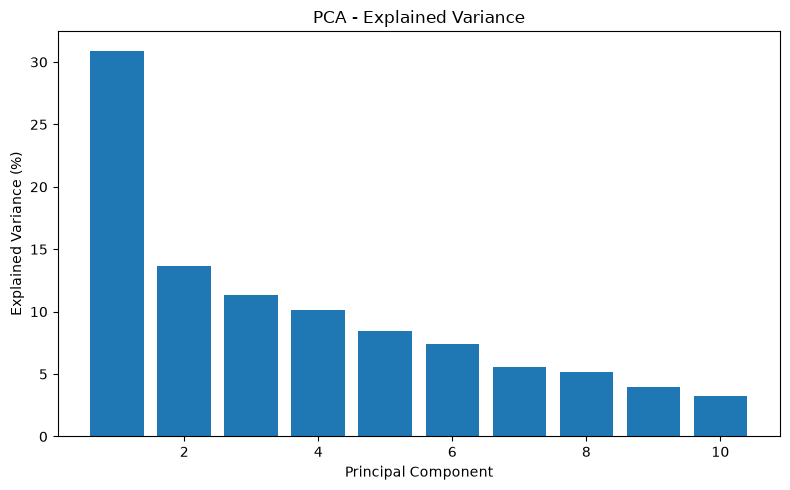

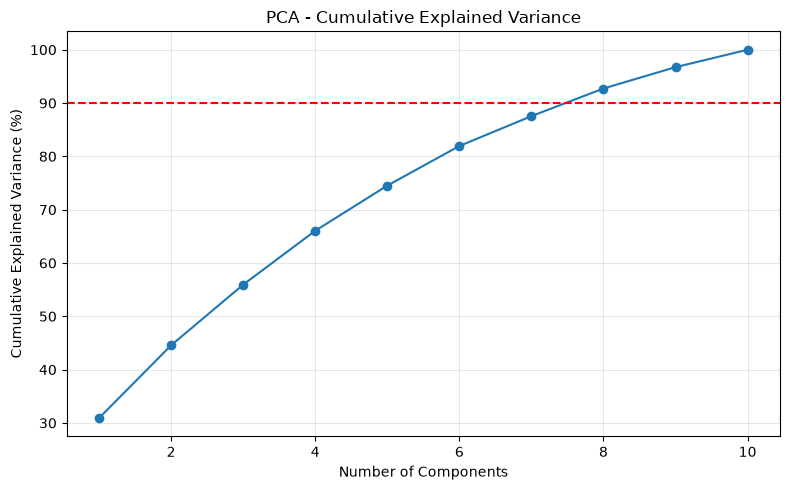

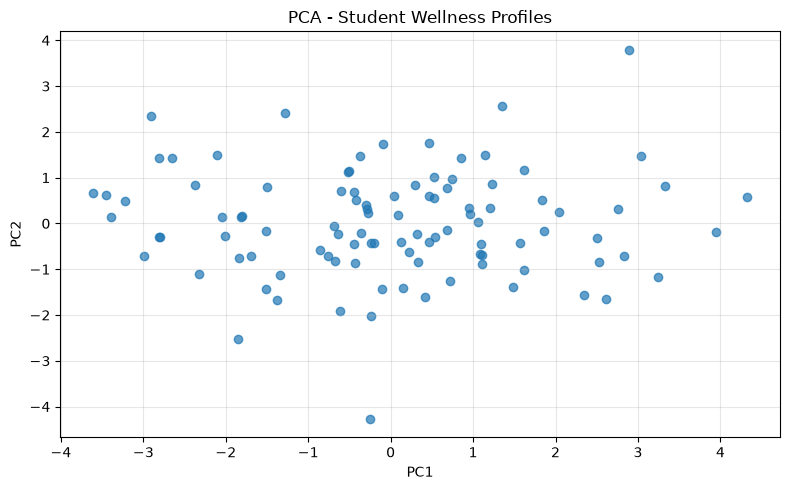

In [20]:

import matplotlib.pyplot as plt

# Explained variance
plt.figure(figsize=(8, 5))
plt.bar(
    np.arange(1, len(explained_ratio) + 1),
    explained_ratio * 100
)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("PCA - Explained Variance")
plt.tight_layout()
plt.show()

# Cumulative explained variance
plt.figure(figsize=(8, 5))
plt.plot(
    np.arange(1, len(cumulative_ratio) + 1),
    cumulative_ratio * 100,
    marker="o"
)
plt.axhline(90, linestyle="--", color="red")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA - Cumulative Explained Variance")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# First two principal components
plt.figure(figsize=(8, 5))
plt.scatter(T[:, 0], T[:, 1], alpha=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Student Wellness Profiles")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [21]:

from sklearn.decomposition import PCA

sklearn_pca = PCA(n_components=k)
sklearn_scores = sklearn_pca.fit_transform(Z)

print(
    "Explained variance matches sklearn:",
    np.allclose(
        explained_ratio[:k],
        sklearn_pca.explained_variance_ratio_
    )
)

print(
    "Projected component magnitudes match:",
    np.allclose(
        np.abs(T),
        np.abs(sklearn_scores),
        atol=1e-5
    )
)


Explained variance matches sklearn: True
Projected component magnitudes match: True


# Linear Discriminant Analysis (LDA)

In [22]:

from sklearn.model_selection import train_test_split

# Define LDA predictors
lda_features = [
    "sleep_hours",
    "screen_hours",
    "water_litres",
    "evening_energy",
    "digestive_discomfort"
]

raw_feature_map = {
    "sleep_hours": "sleep_raw",
    "screen_hours": "entertainment_screen_raw",
    "water_litres": "water_raw"
}

# Reconstruct numerical features from raw responses
X_lda = pd.DataFrame(index=cleaned.index)

for feature in lda_features:
    if feature in raw_feature_map:
        raw_col = raw_feature_map[feature]
        X_lda[feature] = pd.to_numeric(
            cleaned[raw_col].apply(clean_number),
            errors="coerce"
        )
    else:
        X_lda[feature] = pd.to_numeric(
            cleaned[feature],
            errors="coerce"
        )

# Define exploratory target
stress = pd.to_numeric(
    cleaned["stress_anxious"],
    errors="coerce"
)

valid = stress.isin([1, 2, 3, 4, 5])

X_lda = X_lda.loc[valid]
y_lda = (stress.loc[valid] >= 4).astype(int)

# Split BEFORE fitting preprocessing parameters
X_train, X_test, y_train, y_test = train_test_split(
    X_lda,
    y_lda,
    test_size=0.25,
    random_state=42,
    stratify=y_lda
)

A = X_train.to_numpy(dtype=float)
B = X_test.to_numpy(dtype=float)

# IQR treatment using training data only
for j in range(3):
    valid_train = A[:, j][np.isfinite(A[:, j])]

    q1 = np.percentile(valid_train, 25)
    q3 = np.percentile(valid_train, 75)

    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    A[:, j] = np.where(
        (A[:, j] < lower) | (A[:, j] > upper),
        np.nan,
        A[:, j]
    )

    B[:, j] = np.where(
        (B[:, j] < lower) | (B[:, j] > upper),
        np.nan,
        B[:, j]
    )

# Median imputation using training data only
medians = np.nanmedian(A, axis=0)

A = np.where(np.isnan(A), medians, A)
B = np.where(np.isnan(B), medians, B)

# Manual standardization
means = np.sum(A, axis=0) / len(A)

stds = np.sqrt(
    np.sum((A - means) ** 2, axis=0) / len(A)
)

if np.any(stds == 0):
    raise ValueError("Constant feature detected")

A = (A - means) / stds
B = (B - means) / stds

y_train_array = y_train.to_numpy()
y_test_array = y_test.to_numpy()

print("Training shape:", A.shape)
print("Testing shape:", B.shape)

print("Training means:",
      np.round(np.mean(A, axis=0), 4))

print("Training standard deviations:",
      np.round(np.std(A, axis=0), 4))


Training shape: (75, 5)
Testing shape: (25, 5)
Training means: [-0.  0.  0.  0. -0.]
Training standard deviations: [1. 1. 1. 1. 1.]


In [23]:

classes = np.unique(y_train_array)

overall_mean = np.sum(A, axis=0) / len(A)

SW = np.zeros((A.shape[1], A.shape[1]))
SB = np.zeros((A.shape[1], A.shape[1]))

class_means = {}

for c in classes:
    Xc = A[y_train_array == c]

    mean_c = np.sum(Xc, axis=0) / len(Xc)
    class_means[c] = mean_c

    centered = Xc - mean_c

    SW += centered.T @ centered

    diff = (mean_c - overall_mean).reshape(-1, 1)
    SB += len(Xc) * (diff @ diff.T)

print("Within-class scatter matrix:")
display(pd.DataFrame(SW).round(3))

print("Between-class scatter matrix:")
display(pd.DataFrame(SB).round(3))

Within-class scatter matrix:


,0,1,2,3,4
0,71.720,2.549,0.649,21.303,6.405
1,2.549,74.146,-2.113,3.908,-11.237
2,0.649,-2.113,74.624,12.427,7.831
3,21.303,3.908,12.427,70.253,-0.741
4,6.405,-11.237,7.831,-0.741,74.353


Between-class scatter matrix:


,0,1,2,3,4
0,3.280,-1.673,1.111,3.946,-1.457
1,-1.673,0.854,-0.567,-2.013,0.743
2,1.111,-0.567,0.376,1.336,-0.493
3,3.946,-2.013,1.336,4.747,-1.752
4,-1.457,0.743,-0.493,-1.752,0.647


In [24]:

# Regularization for numerical stability
regularization = 1e-6 * np.trace(SW) / SW.shape[0]

SW_reg = SW + regularization * np.eye(SW.shape[0])

mean_difference = class_means[1] - class_means[0]

w = np.linalg.solve(SW_reg, mean_difference)

# Normalize direction
w = w / np.linalg.norm(w)

print("LDA discriminant direction:")
display(
    pd.DataFrame({
        "Feature": lda_features,
        "Weight": w
    }).round(4)
)


LDA discriminant direction:


,Feature,Weight
0,sleep_hours,-0.5027
1,screen_hours,0.4228
2,water_litres,-0.1280
3,evening_energy,-0.6328
4,digestive_discomfort,0.3894


In [25]:

# Pooled covariance matrix
pooled_cov = SW / (len(A) - len(classes))

ridge = 1e-6 * np.trace(pooled_cov) / pooled_cov.shape[0]

pooled_cov += ridge * np.eye(pooled_cov.shape[0])

inv_cov_diff = np.linalg.solve(
    pooled_cov,
    class_means[1] - class_means[0]
)

# Empirical class probabilities
prior0 = np.mean(y_train_array == 0)
prior1 = np.mean(y_train_array == 1)

# Linear decision boundary
intercept = (
    -0.5 * (
        class_means[1] + class_means[0]
    ) @ inv_cov_diff
    + np.log(prior1 / prior0)
)

decision_scores = B @ inv_cov_diff + intercept

y_pred_manual = (decision_scores >= 0).astype(int)

# Manual accuracy
accuracy = np.sum(
    y_pred_manual == y_test_array
) / len(y_test_array)

# Manual balanced accuracy
recalls = []

for c in classes:
    mask = y_test_array == c
    recalls.append(
        np.mean(y_pred_manual[mask] == c)
    )

balanced_accuracy = np.mean(recalls)

print("Manual LDA Accuracy:", round(accuracy, 4))
print("Manual Balanced Accuracy:",
      round(balanced_accuracy, 4))


Manual LDA Accuracy: 0.68
Manual Balanced Accuracy: 0.5331


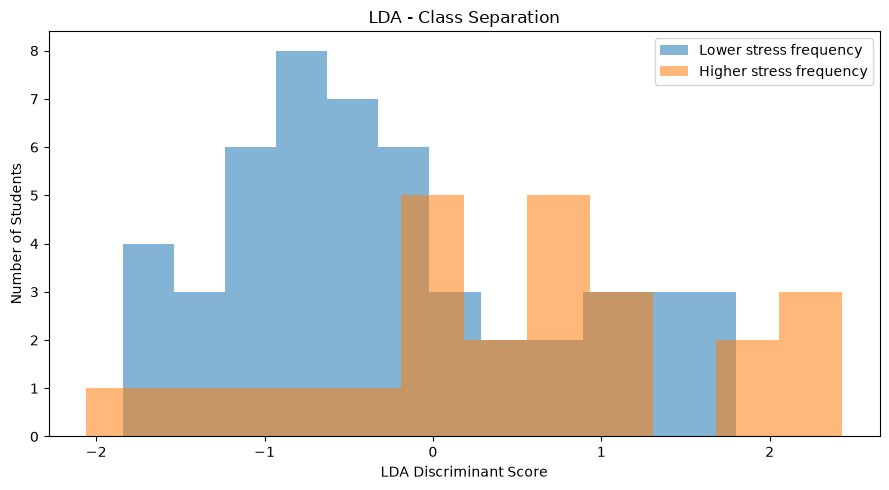

In [26]:

# Project onto discriminant direction
train_projection = A @ w
test_projection = B @ w

plt.figure(figsize=(9, 5))

for c, label in [
    (0, "Lower stress frequency"),
    (1, "Higher stress frequency")
]:
    mask = y_train_array == c

    plt.hist(
        train_projection[mask],
        bins=12,
        alpha=0.55,
        label=label
    )

plt.xlabel("LDA Discriminant Score")
plt.ylabel("Number of Students")
plt.title("LDA - Class Separation")
plt.legend()
plt.tight_layout()
plt.show()


In [27]:

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# A and B have already been standardized
# using training-set statistics.
sklearn_lda = LinearDiscriminantAnalysis(
    solver="lsqr"
)

sklearn_lda.fit(A, y_train_array)

y_pred_sklearn = sklearn_lda.predict(B)

print("Manual Accuracy:", round(accuracy, 4))

print(
    "Sklearn Accuracy:",
    round(
        np.mean(y_pred_sklearn == y_test_array),
        4
    )
)

print(
    "Prediction Agreement:",
    round(
        np.mean(y_pred_manual == y_pred_sklearn),
        4
    )
)

print(
    "Manual Confusion Matrix:"
)

for actual in classes:
    print([
        np.sum(
            (y_test_array == actual)
            & (y_pred_manual == predicted)
        )
        for predicted in classes
    ])


Manual Accuracy: 0.68
Sklearn Accuracy: 0.68
Prediction Agreement: 1.0
Manual Confusion Matrix:
[np.int64(16), np.int64(1)]
[np.int64(7), np.int64(1)]


# LDA Preprocessing and Evaluation
## step-1: Checking for Data Leakage 

In [28]:

# Check which original responses could not be parsed
# or were replaced during outlier treatment.

for raw_col, clean_col in [
    ("sleep_raw", "sleep_hours"),
    ("entertainment_screen_raw", "screen_hours"),
    ("water_raw", "water_litres")
]:
    parsed = pd.to_numeric(
        cleaned[raw_col].apply(clean_number),
        errors="coerce"
    )

    stored = pd.to_numeric(
        cleaned[clean_col],
        errors="coerce"
    )

    changed = parsed.isna() | ~np.isclose(
        parsed.fillna(-999999),
        stored.fillna(-999999)
    )

    print(f"{clean_col}: {changed.sum()} values "
          "requiring imputation or outlier replacement")


sleep_hours: 4 values requiring imputation or outlier replacement
screen_hours: 3 values requiring imputation or outlier replacement
water_litres: 6 values requiring imputation or outlier replacement
